   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


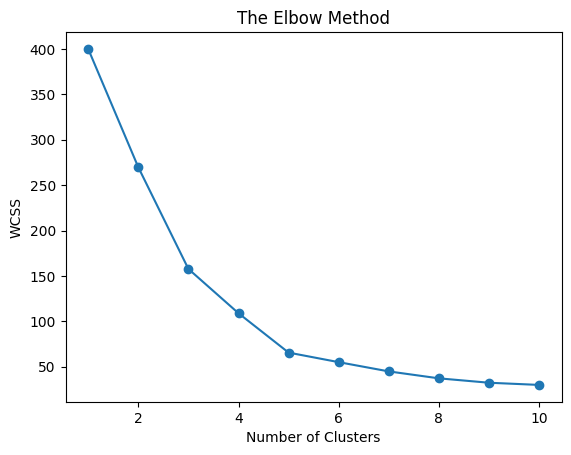


Cluster Centroids (Scaled):
[[-0.20091257 -0.02645617]
 [ 0.99158305  1.23950275]
 [-1.32954532  1.13217788]
 [ 1.05500302 -1.28443907]
 [-1.30751869 -1.13696536]]


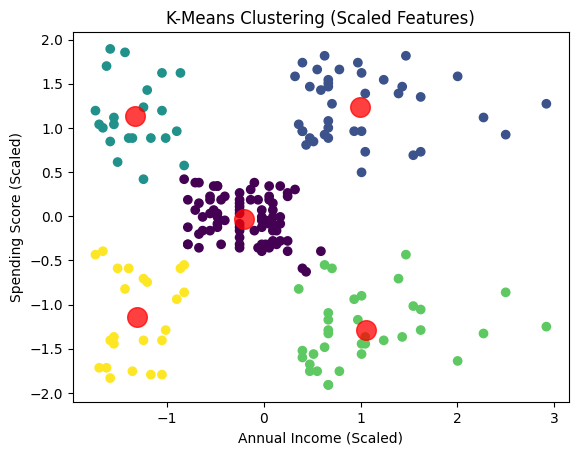


Cluster Assignments:
   CustomerID  Cluster
0           1        4
1           2        2
2           3        4
3           4        2
4           5        4

Customers in Each Cluster:
Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64
Clustering completed successfully!


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from pandas import read_csv

# 1. Load the Dataset
df = read_csv('Mall_Customers.csv')
print(df.head())

# 2. Select Features
x = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 3. Scale Data
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# 4. Elbow Method (using scaled data)
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(x_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

# 5. Apply K-Means (using scaled data)
k_means = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = k_means.fit_predict(x_scaled)
df["Cluster"] = labels

# 6. Display Cluster Centroids (inverse transform to see original scale if desired, or keep scaled)
print("\nCluster Centroids (Scaled):")
print(k_means.cluster_centers_)

# 7. Visualize Clusters
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c=labels, cmap='viridis')
plt.scatter(
    k_means.cluster_centers_[:, 0],
    k_means.cluster_centers_[:, 1],
    c='red',
    marker='o',
    s=200,
    alpha=0.75
)
plt.title('K-Means Clustering (Scaled Features)')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.show()

# 8. Display Results
print("\nCluster Assignments:")
print(df[["CustomerID", "Cluster"]].head())

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts())

# 9. Save Results
df.to_csv("Clustered_Customers.csv", index=False)
print("Clustering completed successfully!")
